# Treći zadatak

Dodavanje biblioteka

In [24]:
import numpy as np
import matplotlib.pyplot as plt
import os
import seaborn as sns

from skimage import io
from skimage import util
from skimage import color


from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report


Generisanje klasa

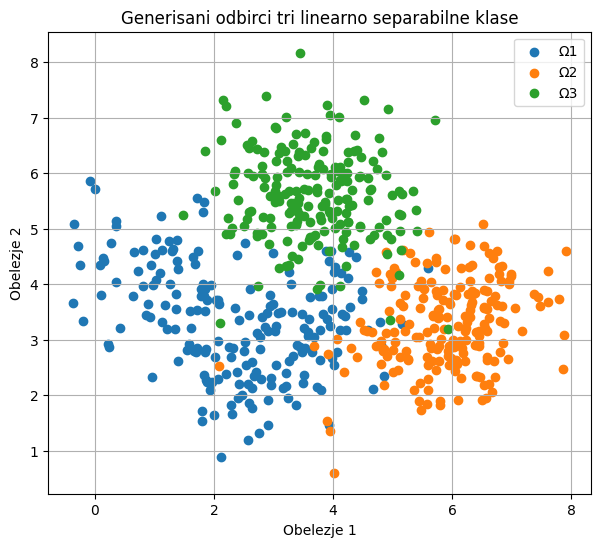

In [12]:
N = 200 #broj odbiraka po klasi

# prva klasa
M11 = np.array([1.5, 3.8]).reshape(-1,1)
M12 = np.array([3.2, 2.9]).reshape(-1,1)

S11 = np.array([[1.1, -0.6], [-0.6, 1.1]])
S12 = [[0.9, 0.4], [0.4, 0.9]]

p11 = 0.5
p12 = 0.5

n11 = int(p11*N)
n12 = int(p12*N)
data11 = np.random.multivariate_normal(M11.reshape(-1), S11, n11)
data12 = np.random.multivariate_normal(M12.reshape(-1), S12, n12)
data1 = np.vstack((data11, data12))

# druga klasa
M2 = np.array([5.8, 3.2])
S2 = np.array([[0.7, 0.15],[0.15, 0.6]])
data2 = np.random.multivariate_normal(M2, S2, N)

# treća klasa
M3 = np.array([3.6,5.6])
S3 = np.array([[0.6, -0.1],[-0.1, 0.7]])
data3 = np.random.multivariate_normal(M3, S3, N)

# crtanje
plt.figure(figsize=(7, 6))
plt.scatter(data1[:, 0], data1[:, 1], label="Ω1")
plt.scatter(data2[:, 0], data2[:, 1], label="Ω2")
plt.scatter(data3[:, 0], data3[:, 1], label="Ω3")

plt.title("Generisani odbirci tri linearno separabilne klase")
plt.xlabel("Obelezje 1")
plt.ylabel("Obelezje 2")
plt.legend()
plt.grid(True)
plt.show()

Linearni klasifikator (izabrana metoda resupstitucije)

In [25]:
# funkcija za pronalazak najboljih vrednosti V i v0
def best_values(data_first, data_second, S_first, S_second, M_first, M_second):
    s_vals = np.arange(0, 1, 0.01)
    Neps_s = []
    v0_opt = []

    for s in s_vals:
        V = np.linalg.inv(s * S_first + (1 - s) * S_second) @ (M_second - M_first)
        Y_first = V.T @ data_first.T
        Y_second = V.T @ data_second.T

        Y = np.sort(np.concatenate((Y_first, Y_second)))
        n_total = len(Y)
        v0 = np.zeros(n_total - 1) # optimalne vrednosti v0 za fiksno s
        Neps = np.zeros(n_total - 1) # optimalne vrednosti N_epsilon za fiksno s

        for j in range(n_total - 1):
            v0[j] = -(Y[j] + Y[j+1]) / 2
            Neps[j] += np.sum(Y_first > -v0[j])
            Neps[j] += np.sum(Y_second < -v0[j])

        Neps_s.append(np.min(Neps))
        v0_opt.append(v0[np.argmin(Neps)])

    i = np.argmin(Neps_s)
    s_best = s_vals[i]
    V_best = np.linalg.inv(s_best * S_first + (1 - s_best) * S_second) @ (M_second - M_first)
    v0_best = v0_opt[i]
    return V_best, v0_best

# estimacija parametara pre projektovanja klasifikatora (ovo nije neophodno jer smo mi zadali parametre)
M1_est = np.mean(data1, axis=0)
M2_est = np.mean(data2, axis=0)
M3_est = np.mean(data3, axis=0)
S1_est = np.cov(data1.T)
S2_est = np.cov(data2.T)
S3_est = np.cov(data3.T)

# projektovanje tri klasifikatora
V12, v0_12 = best_values(data1, data2, S1_est, S2_est, M1_est, M2_est) # "odvaja" klase 1 i 2
V13, v0_13 = best_values(data1, data3, S1_est, S3_est, M1_est, M3_est) # "odvaja" klase 1 i 3
V23, v0_23 = best_values(data2, data3, S2_est, S3_est, M2_est, M3_est) # "odvaja" klase 2 i 3

# funkcija za određivanje klase kojoj pripada odbirak
def classify(x):
    votes = [0,0,0]

    # Klasa 1 vs Klasa 2
    if V12.T @ x + v0_12 > 0:
        votes[1] += 1  
    else:
        votes[0] += 1 

    # Klasa 1 vs Klasa 3
    if V13.T @ x + v0_13 > 0:
        votes[2] += 1  
    else:
        votes[0] += 1 

    # Klasa 2 vs Klasa 3
    if V23.T @ x + v0_23 > 0:
        votes[2] += 1  
    else:
        votes[1] += 1  

    return np.argmax(votes)




Matrica konfuzije

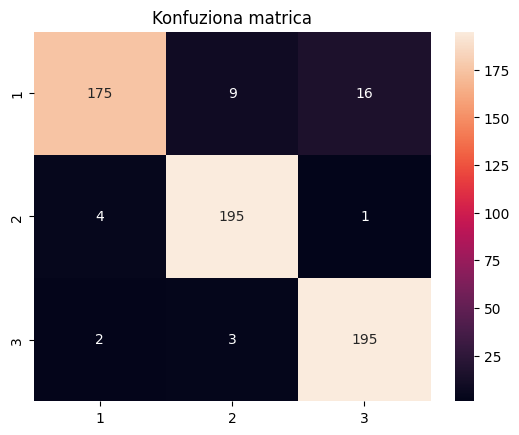

In [26]:
X = np.vstack((data1, data2, data3))
y_true = np.array([0]*N + [1]*N + [2]*N) 
y_pred = np.array([classify(x) for x in X])

cm = confusion_matrix(y_true,y_pred)
plt.figure()
sns.heatmap(cm, annot=True, fmt='g',xticklabels=[1,2,3], yticklabels=[1,2,3])
plt.title('Konfuziona matrica')
plt.show()

Linearni klasifikatori

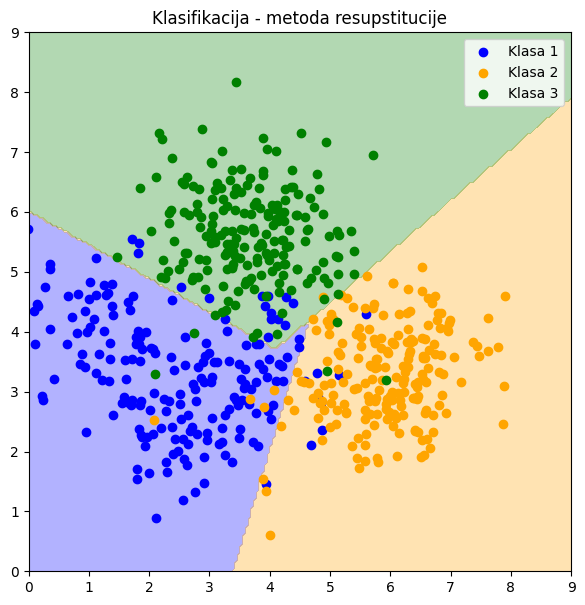

In [27]:
x, y = np.meshgrid(np.linspace(0,9,200), np.linspace(0,9,200))
Z = np.zeros(x.shape)

for i in range(x.shape[0]):
    for j in range(x.shape[1]):
        Z[i,j] = classify(np.array([x[i,j], y[i,j]]))

plt.figure(figsize=(7,7))
plt.contourf(x, y, Z, alpha=0.3, levels=[-0.5,0.5,1.5,2.5], colors=['blue','orange','green'])
plt.scatter(data1[:,0], data1[:,1], c='blue', label="Klasa 1")
plt.scatter(data2[:,0], data2[:,1], c='orange', label="Klasa 2")
plt.scatter(data3[:,0], data3[:,1], c='green', label="Klasa 3")
plt.legend()
plt.title("Klasifikacija - metoda resupstitucije")
plt.xlim([0,9])
plt.ylim([0,9])
plt.show()

Klasifikator metodom želejnog izlaza

/var/folders/4g/g003h3696xb2x1hx9m48dv8w0000gn/T/ipykernel_45985/3977482342.py:8: RuntimeWarning: divide by zero encountered in matmul
  W = np.linalg.inv(U@U.T)@U@Gamma
/var/folders/4g/g003h3696xb2x1hx9m48dv8w0000gn/T/ipykernel_45985/3977482342.py:8: RuntimeWarning: overflow encountered in matmul
  W = np.linalg.inv(U@U.T)@U@Gamma
/var/folders/4g/g003h3696xb2x1hx9m48dv8w0000gn/T/ipykernel_45985/3977482342.py:8: RuntimeWarning: invalid value encountered in matmul
  W = np.linalg.inv(U@U.T)@U@Gamma


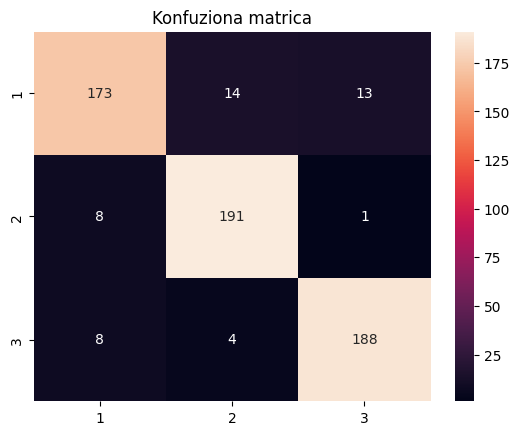

In [ ]:
# funkcija za pronalazak parametara matrice W
def best_params2(data_first, data_second, N):
    x0 = np.ones((1,2*N))
    x0[0,0:N] = x0[0,0:N]*(-1)
    X = np.concatenate((data_first*(-1),data_second),axis=0).T
    U = np.concatenate((x0,X), axis=0)
    Gamma = np.ones((1,2*N)).T
    W = np.linalg.inv(U@U.T)@U@Gamma
    
    v0 = W[0]
    v1 = W[1]
    v2 = W[2]
    
    return v0,v1,v2 

# parametri klasifikatora između svake dve klase
v0_12, v1_12, v2_12 = best_params2(data1, data2, 200)
v0_23, v1_23, v2_23 = best_params2(data2, data3, 200)
v0_13, v1_13, v2_13 = best_params2(data1, data3, 200)

# funkcija za određivanje klase kojoj pripada odbirak
def classify2(x):
    votes = [0,0,0]

    # Klasa 1 vs Klasa 2
    if v0_12 + v1_12*x[0] + v2_12*x[1] > 0:
        votes[1] += 1  
    else:
        votes[0] += 1  

    # Klasa 1 vs Klasa 3
    if v0_13 + v1_13*x[0] + v2_13*x[1] > 0:
        votes[2] += 1  
    else:
        votes[0] += 1  

    # Klasa 2 vs Klasa 3
    if v0_23 + v1_23*x[0] + v2_23*x[1] > 0:
        votes[2] += 1  
    else:
        votes[1] += 1  

    return np.argmax(votes)

X = np.vstack((data1, data2, data3))
y_true = np.array([0]*N + [1]*N + [2]*N) 
y_pred = np.array([classify2(x) for x in X])

# konfuziona matrica
cm = confusion_matrix(y_true,y_pred)
plt.figure()
sns.heatmap(cm, annot=True, fmt='g',xticklabels=[1,2,3], yticklabels=[1,2,3])
plt.title('Konfuziona matrica')
plt.show()

Uticaj elemenata u matrici željenih izlaza na konačnu formu linearnog klasifikatora



/var/folders/4g/g003h3696xb2x1hx9m48dv8w0000gn/T/ipykernel_45985/2124943053.py:6: RuntimeWarning: divide by zero encountered in matmul
  W = np.linalg.inv(U@U.T)@U@gama
/var/folders/4g/g003h3696xb2x1hx9m48dv8w0000gn/T/ipykernel_45985/2124943053.py:6: RuntimeWarning: overflow encountered in matmul
  W = np.linalg.inv(U@U.T)@U@gama
/var/folders/4g/g003h3696xb2x1hx9m48dv8w0000gn/T/ipykernel_45985/2124943053.py:6: RuntimeWarning: invalid value encountered in matmul
  W = np.linalg.inv(U@U.T)@U@gama


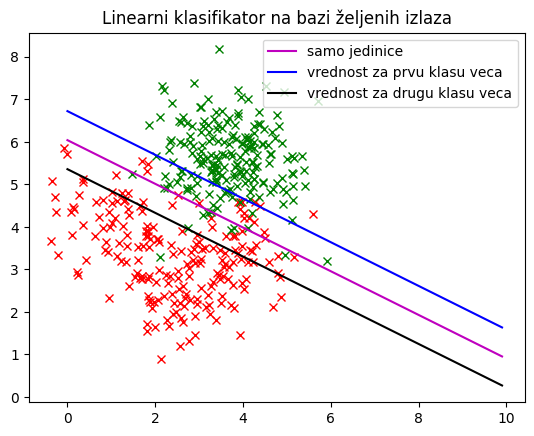

In [34]:
def test_values(gama, data_first, data_second, N):
    x0 = np.ones((1,2*N))
    x0[0,0:N] = x0[0,0:N]*(-1)
    X = np.concatenate((data_first*(-1),data_second),axis=0).T
    U = np.concatenate((x0,X), axis=0)
    W = np.linalg.inv(U@U.T)@U@gama
    
    v0 = W[0]
    v1 = W[1]
    v2 = W[2]
    
    return v0,v1,v2 

gama1 = np.ones((1,200*2)).T
gama2 = np.ones((1,200*2)).T
gama2[0:200,0] = gama2[0:200,0]*2
gama3 = np.ones((1,200*2)).T
gama3[200:400,0] = gama2[200:400,0]*2

v01,v11,v21 = test_values(gama1, data1, data3, 200)
v02,v12,v22 = test_values(gama2, data1, data3, 200)
v03,v13,v23 = test_values(gama3, data1, data3, 200)

# crtanje
x11 = np.arange(0,10,0.1)
x21 = -(v01+v11*x11)/v21

x12 = np.arange(0,10,0.1)
x22 = -(v02+v12*x12)/v22

x13 = np.arange(0,10,0.1)
x23 = -(v03+v13*x13)/v23

plt.figure()
plt.plot(data1[:,0],data1[:,1],'rx')
plt.plot(data3[:,0],data3[:,1],'gx')
plt.plot(x11,x21,'m', label='samo jedinice')
plt.plot(x12,x22,'b', label='vrednost za prvu klasu veca')
plt.plot(x13,x23,'k',label='vrednost za drugu klasu veca')
plt.legend()
plt.title('Linearni klasifikator na bazi željenih izlaza');